# Exploratory Data Analysis of the Grammy Awards Dataset

In [14]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px


In [15]:
# Load Grammy Awards data
grammy_df = pd.read_csv(
    "../../sql/Grammys_db/seed/the_grammy_awards.csv"
)

print("Grammy dataset:", grammy_df.shape)
print("-" * 50)
grammy_df.info()

Grammy dataset: (4810, 10)
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4810 entries, 0 to 4809
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   year          4810 non-null   int64 
 1   title         4810 non-null   object
 2   published_at  4810 non-null   object
 3   updated_at    4810 non-null   object
 4   category      4810 non-null   object
 5   nominee       4804 non-null   object
 6   artist        2970 non-null   object
 7   workers       2620 non-null   object
 8   img           3443 non-null   object
 9   winner        4810 non-null   bool  
dtypes: bool(1), int64(1), object(8)
memory usage: 343.0+ KB


In [16]:
grammy_df.head()


,year,title,published_at,updated_at,category,nominee,artist,workers,img,winner
0,2019,62nd Annual GRAMMY Awards (2019),2020-05-19T05:10:28-07:00,2020-05-19T05:10:28-07:00,Record Of The Year,Bad Guy,Billie Eilish,"Finneas O'Connell, producer; Rob Kinelski & Fi...",https://www.grammy.com/sites/com/files/styles/...,True
1,2019,62nd Annual GRAMMY Awards (2019),2020-05-19T05:10:28-07:00,2020-05-19T05:10:28-07:00,Record Of The Year,"Hey, Ma",Bon Iver,"BJ Burton, Brad Cook, Chris Messina & Justin V...",https://www.grammy.com/sites/com/files/styles/...,True
2,2019,62nd Annual GRAMMY Awards (2019),2020-05-19T05:10:28-07:00,2020-05-19T05:10:28-07:00,Record Of The Year,7 rings,Ariana Grande,"Charles Anderson, Tommy Brown, Michael Foster ...",https://www.grammy.com/sites/com/files/styles/...,True
3,2019,62nd Annual GRAMMY Awards (2019),2020-05-19T05:10:28-07:00,2020-05-19T05:10:28-07:00,Record Of The Year,Hard Place,H.E.R.,"Rodney “Darkchild” Jerkins, producer; Joseph H...",https://www.grammy.com/sites/com/files/styles/...,True
4,2019,62nd Annual GRAMMY Awards (2019),2020-05-19T05:10:28-07:00,2020-05-19T05:10:28-07:00,Record Of The Year,Talk,Khalid,"Disclosure & Denis Kosiak, producers; Ingmar C...",https://www.grammy.com/sites/com/files/styles/...,True


# Categorical attributes

In [17]:
# Categorical attributes
grammy_df.select_dtypes(include=["object", "string"]).describe()

,title,published_at,updated_at,category,nominee,artist,workers,img
count,4810,4810,4810,4810,4804,2970,2620,3443
unique,62,4,10,638,4131,1658,2366,1463
top,62nd Annual GRAMMY Awards (2019),2017-11-28T00:03:45-08:00,2019-09-10T01:08:19-07:00,Song Of The Year,Bridge Over Troubled Water,(Various Artists),"John Williams, composer (John Williams)",https://www.grammy.com/sites/com/files/styles/...
freq,433,4205,778,70,7,66,20,26


### Winner Distribution Analysis

The analysis of the `winner` column revealed that all 4,810 records (100%) are marked as `True`. No `False` values were found in the dataset. This indicates that the dataset contains only records labeled as winners, so it is not possible to compare winning and non-winning records using this column. 

In [18]:
grammy_df["winner"].unique()

array([ True])

### Missing Values Analysis

The dataset contains missing values mainly in the `workers` (2,190), `artist` (1,840), and `img` (1,367) columns. The `nominee` column has only 6 missing values, while the remaining columns have no missing data.

In [19]:
grammy_df.isnull().sum()

year               0
title              0
published_at       0
updated_at         0
category           0
nominee            6
artist          1840
workers         2190
img             1367
winner             0
dtype: int64

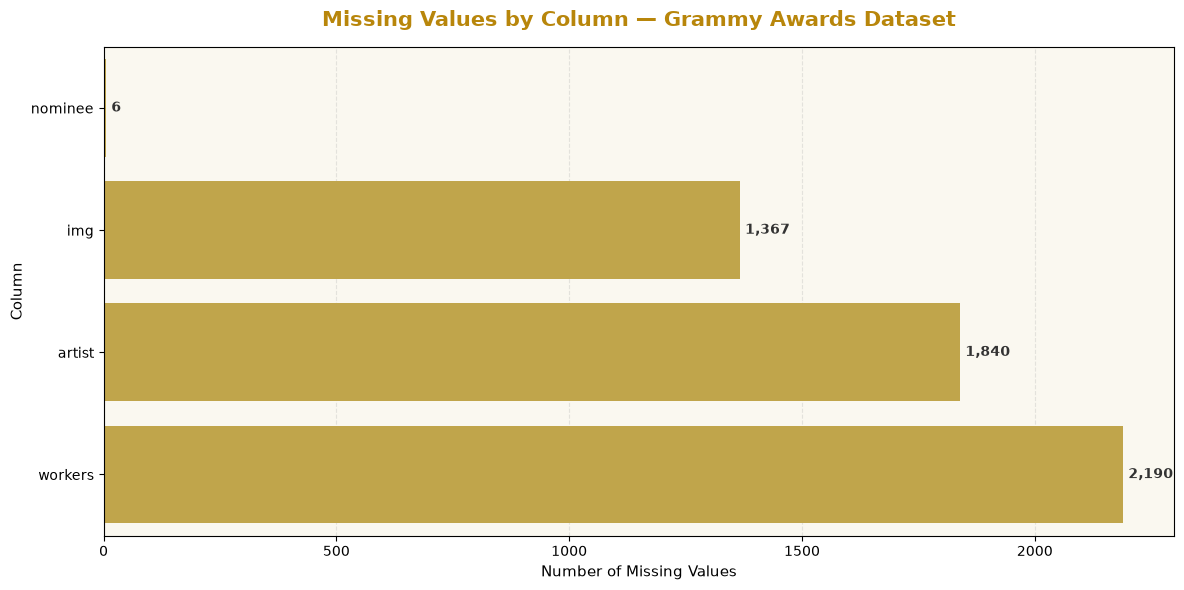

In [20]:
# Missing Values Analysis (Grammy Awards)
grammy_nulls = grammy_df.isnull().sum()
grammy_nulls = grammy_nulls[grammy_nulls > 0].sort_values()

# Visualize missing values
if not grammy_nulls.empty:
    plt.figure(figsize=(12, 6))

    sns.barplot(
        x=grammy_nulls.values,
        y=grammy_nulls.index,
        color="#D4AF37"  # Grammy gold
    )

    # Add labels with the number of missing values
    for index, value in enumerate(grammy_nulls.values):
        plt.text(
            value,
            index,
            f" {value:,}",
            va="center",
            fontsize=10,
            fontweight="bold",
            color="#333333"
        )

    plt.title(
        "Missing Values by Column — Grammy Awards Dataset",
        fontsize=15,
        fontweight="bold",
        color="#B8860B",
        pad=15
    )

    plt.xlabel("Number of Missing Values", fontsize=11)
    plt.ylabel("Column", fontsize=11)

    plt.gca().set_facecolor("#FAF8F0")
    plt.grid(axis="x", linestyle="--", alpha=0.3)
    plt.gca().set_axisbelow(True)

    plt.tight_layout()
    plt.show()

else:
    print("No missing values found in the Grammy Awards dataset.")

## Duplicate records

In [21]:
# Duplicate records
print("Duplicate records:", grammy_df.duplicated().sum())

Duplicate records: 0


=== Missing Values Summary ===
         missing_values  missing_percentage
nominee               6                0.12
artist             1840               38.25
workers            2190               45.53
img                1367               28.42

Total missing values: 5403


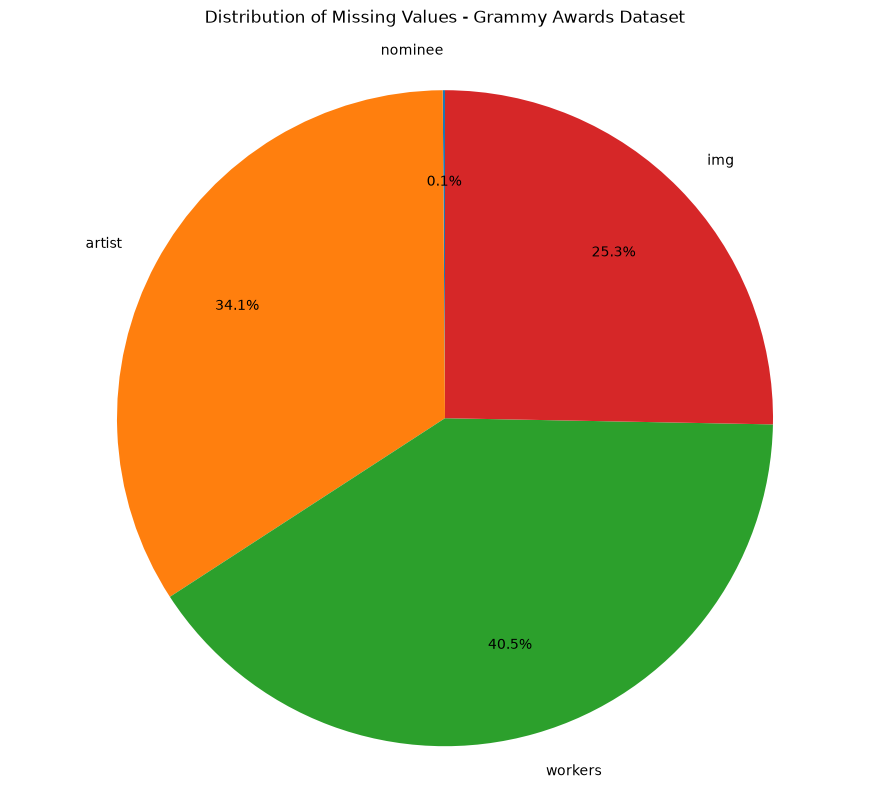

In [22]:

# Missing values summary
missing_columns = ["nominee", "artist", "workers", "img"]

missing_summary = pd.DataFrame({
    "missing_values": grammy_df[missing_columns].isnull().sum(),
    "missing_percentage": (
        grammy_df[missing_columns].isnull().sum()
        / len(grammy_df) * 100
    ).round(2)
})

print("=== Missing Values Summary ===")
print(missing_summary.to_string())

print(f"\nTotal missing values: {missing_summary['missing_values'].sum()}")

# Pie chart
missing_values = missing_summary["missing_values"]

fig, ax = plt.subplots(figsize=(9, 8))

ax.pie(
    missing_values,
    labels=missing_values.index,
    autopct="%1.1f%%",
    startangle=90,
    labeldistance=1.12,
    pctdistance=0.72
)

ax.set_title(
    "Distribution of Missing Values - Grammy Awards Dataset",
    pad=25
)

ax.axis("equal")
plt.tight_layout()
plt.show()

